In [1]:
!pip -q install "datasets[audio]" librosa soundfile scikit-learn matplotlib seaborn

print("Libraries installed successfully.")

Libraries installed successfully.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

from collections import Counter

from datasets import load_dataset, concatenate_datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [4]:
dataset = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

print("Total samples:", len(dataset))
print("Columns:", dataset.column_names)

README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]

Total samples: 3755
Columns: ['path', 'audio', 'label', 'notes']


In [5]:
print("Label distribution:")

for label, count in Counter(dataset["label"]).items():
    if label == 0:
        name = "Bonafide / Real"
    else:
        name = "Spoof / Fake"

    print(label, "=", name, ":", count)

Label distribution:
1 = Spoof / Fake : 3000
0 = Bonafide / Real : 755


In [6]:
real_data = dataset.filter(
    lambda x: int(x["label"]) == 0
)

fake_data = dataset.filter(
    lambda x: int(x["label"]) == 1
)

number_of_samples = min(
    len(real_data),
    len(fake_data)
)

real_data = real_data.shuffle(
    seed=SEED
).select(
    range(number_of_samples)
)

fake_data = fake_data.shuffle(
    seed=SEED
).select(
    range(number_of_samples)
)

dataset = concatenate_datasets(
    [real_data, fake_data]
).shuffle(seed=SEED)

print("Real samples:", len(real_data))
print("Fake samples:", len(fake_data))
print("Total balanced samples:", len(dataset))

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Real samples: 755
Fake samples: 755
Total balanced samples: 1510


Real samples: 755
Fake samples: 755


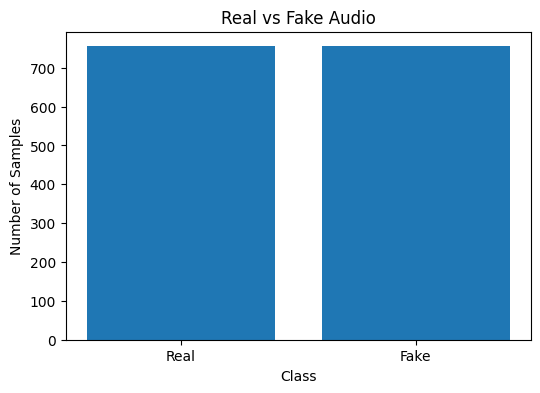

In [8]:
# CELL 7 - Check class distribution

from collections import Counter

# Count the labels
label_counts = Counter(dataset["label"])

real_count = label_counts[0]
fake_count = label_counts[1]

print("Real samples:", real_count)
print("Fake samples:", fake_count)

# Create the graph
plt.figure(figsize=(6, 4))

plt.bar(
    ["Real", "Fake"],
    [real_count, fake_count]
)

plt.title("Real vs Fake Audio")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.show()

In [9]:
def create_mel_spectrogram(audio, sample_rate):

    # Convert stereo audio to mono
    if audio.ndim > 1:
        audio = np.mean(audio, axis=0)

    # Convert sample rate to 16 kHz
    if sample_rate != 16000:
        audio = librosa.resample(
            audio,
            orig_sr=sample_rate,
            target_sr=16000
        )

    # Create Mel-spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=16000,
        n_mels=128,
        n_fft=1024,
        hop_length=256
    )

    # Convert power to decibels
    mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # Make every spectrogram the same size
    if mel.shape[1] < 256:

        padding = 256 - mel.shape[1]

        mel = np.pad(
            mel,
            ((0, 0), (0, padding)),
            mode="constant"
        )

    else:

        mel = mel[:, :256]

    return mel

In [10]:
sample = dataset[0]

audio = sample["audio"]

mel = create_mel_spectrogram(
    audio["array"],
    audio["sampling_rate"]
)

print("Spectrogram shape:", mel.shape)
print("Label:", sample["label"])

Spectrogram shape: (128, 256)
Label: 0


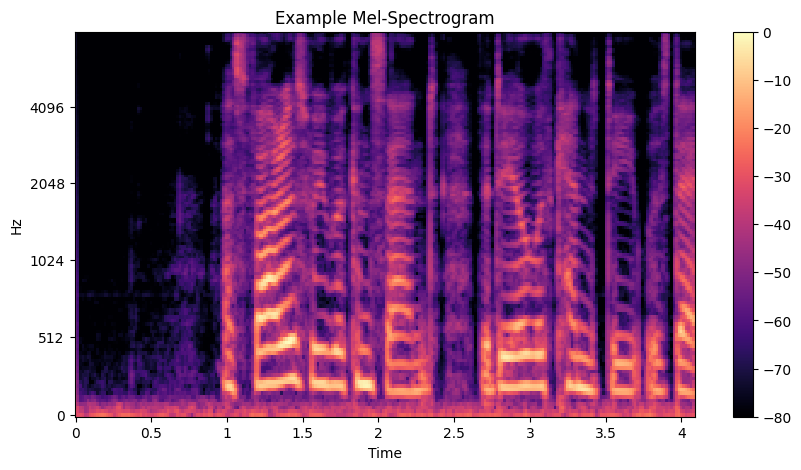

In [11]:
plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mel,
    sr=16000,
    hop_length=256,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar()

plt.title("Example Mel-Spectrogram")

plt.show()

In [13]:
# CELL 11 - Convert audio into Mel-spectrograms

X = []
y = []

# Number of samples to use
# 1000 real + 1000 fake = 2000 total
SAMPLES_PER_CLASS = 1000

real_samples = dataset.filter(
    lambda x: int(x["label"]) == 0
).shuffle(seed=SEED).select(
    range(min(SAMPLES_PER_CLASS,
              len(dataset.filter(lambda x: int(x["label"]) == 0))))
)

fake_samples = dataset.filter(
    lambda x: int(x["label"]) == 1
).shuffle(seed=SEED).select(
    range(min(SAMPLES_PER_CLASS,
              len(dataset.filter(lambda x: int(x["label"]) == 1))))
)

# Combine real and fake samples
cnn_dataset = concatenate_datasets(
    [real_samples, fake_samples]
).shuffle(seed=SEED)

print("Samples selected:", len(cnn_dataset))

# Convert audio to Mel-spectrogram
for i, sample in enumerate(cnn_dataset):

    audio = sample["audio"]

    spectrogram = create_mel_spectrogram(
        audio["array"],
        audio["sampling_rate"]
    )

    X.append(spectrogram)
    y.append(int(sample["label"]))

    # Show progress
    if (i + 1) % 100 == 0:
        print(
            "Processed:",
            i + 1,
            "/",
            len(cnn_dataset)
        )

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("\nFeature extraction completed.")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Labels:", Counter(y))

Filter:   0%|          | 0/1510 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1510 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1510 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1510 [00:00<?, ? examples/s]

Samples selected: 1510
Processed: 100 / 1510
Processed: 200 / 1510
Processed: 300 / 1510
Processed: 400 / 1510
Processed: 500 / 1510
Processed: 600 / 1510
Processed: 700 / 1510
Processed: 800 / 1510
Processed: 900 / 1510
Processed: 1000 / 1510
Processed: 1100 / 1510
Processed: 1200 / 1510
Processed: 1300 / 1510
Processed: 1400 / 1510
Processed: 1500 / 1510

Feature extraction completed.
X shape: (1510, 128, 256)
y shape: (1510,)
Labels: Counter({np.int32(0): 755, np.int32(1): 755})


In [14]:
X = (X + 80) / 80

X = np.clip(
    X,
    0,
    1
)

print("Minimum value:", X.min())
print("Maximum value:", X.max())

Minimum value: 0.0
Maximum value: 1.0


In [15]:
X = X[..., np.newaxis]

print("CNN input shape:", X.shape)

CNN input shape: (1510, 128, 256, 1)


In [16]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Testing samples:", len(X_test))

Training samples: 1057
Validation samples: 226
Testing samples: 227


In [17]:
model = Sequential([

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=X_train.shape[1:]
    ),

    MaxPooling2D(
        (2, 2)
    ),

    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D(
        (2, 2)
    ),

    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    MaxPooling2D(
        (2, 2)
    ),

    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        1,
        activation="sigmoid"
    )
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 254, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 127, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 125, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 53760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,881,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,974,209 (26.60 MB)

 Trainable params: 6,974,209 (26.60 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully.")

CNN compiled successfully.


In [20]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_validation,
        y_validation
    ),

    epochs=20,

    batch_size=32
)

Epoch 1/20


KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

In [ ]:
probabilities = model.predict(
    X_test
).ravel()

predictions = (
    probabilities >= 0.5
).astype(int)

print("Predictions generated.")

In [ ]:
accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    predictions,
    zero_division=0
)

print("CNN RESULTS")
print("----------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

In [ ]:
print(
    classification_report(
        y_test,
        predictions,
        target_names=[
            "Bonafide",
            "Spoof"
        ],
        zero_division=0
    )
)

In [ ]:
cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Bonafide",
        "Spoof"
    ],
    yticklabels=[
        "Bonafide",
        "Spoof"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("CNN Confusion Matrix")

plt.show()

In [ ]:
model.save(
    "VoiceGuard_CNN.keras"
)

print("CNN model saved successfully.")

In [ ]:
print("=" * 50)
print("VOICEGUARD CNN COMPLETED")
print("=" * 50)

print("Test Accuracy :", round(accuracy, 4))
print("Precision     :", round(precision, 4))
print("Recall        :", round(recall, 4))
print("F1 Score      :", round(f1, 4))

print("\nModel saved as:")
print("VoiceGuard_CNN.keras")

In [ ]:
# Save CNN results

import os
import pandas as pd

os.makedirs("VoiceGuard_CNN_Results", exist_ok=True)

# Save the trained CNN model
model.save(
    "VoiceGuard_CNN_Results/VoiceGuard_CNN.keras"
)

# Save performance metrics
results = pd.DataFrame([{
    "Model": "CNN",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}])

results.to_csv(
    "VoiceGuard_CNN_Results/CNN_Performance.csv",
    index=False
)

# Save predictions
prediction_data = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions,
    "Spoof_Probability": probabilities
})

prediction_data.to_csv(
    "VoiceGuard_CNN_Results/CNN_Predictions.csv",
    index=False
)

print("======================================")
print("CNN RESULTS SAVED SUCCESSFULLY")
print("======================================")
print("Model: VoiceGuard_CNN.keras")
print("Metrics: CNN_Performance.csv")
print("Predictions: CNN_Predictions.csv")